# Пайплайн POI





In [9]:
try:
    import google.colab
    IN_COLAB = True
    %pip install -q pandas matplotlib seaborn scikit-learn
except ImportError:
    IN_COLAB = False

import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

REPO_URL = "https://github.com/AnastasiaBe1ousova/poi_places_pipeline.git"

def find_project_root():
    paths = []
    if IN_COLAB:
        paths.append(Path("/content/poi_places_pipeline"))
        paths.extend(p.parent.parent for p in Path("/content").rglob("features.py") if p.parent.name == "src")
    paths.extend([Path.cwd(), *Path.cwd().parents])
    for p in paths:
        if (p / "data" / "places.csv").is_file() and (p / "src" / "features.py").is_file():
            return p.resolve()
    return None


ROOT = find_project_root()

feat_file = ROOT / "src" / "features.py"
spec = importlib.util.spec_from_file_location("features", feat_file)
features_mod = importlib.util.module_from_spec(spec)
sys.modules["features"] = features_mod
spec.loader.exec_module(features_mod)
extract_features = features_mod.extract_features

DATA = ROOT / "data" / "places.csv"
df = pd.read_csv(DATA)
print("ROOT:", ROOT)
print("размер:", df.shape)

ROOT: /content/poi_places_pipeline
размер: (79, 6)


## Задание 1. Сбор датасета

**Как выбраны места:** Москва; из `moscow_places.csv` — заведения с высоким рейтингом (топ-18 кафе и топ-18 ресторанов после маппинга категорий). Список известных музеев, парков, театров и достопримечательностей.

**Категории:** `cafe`, `restaurant`, `museum`, `park`, `theatre`, `attraction`.

**Источники:** Яндекс Карты / Бизнес (2022, учебный датасет); описания культуры — Википедия (`wiki_cache.json`).

**Лимиты:** до 18 объектов на категорию общепита; культура - список в `build_dataset.py`


**Поля:** название, категория, описание, отзывы (для еды — рейтинг и цены из Яндекс; текстовых отзывов в выгрузке нет), город, `source`.

In [2]:
df.head(10)

,name,category,description,reviews,city,source
0,WoWфли,cafe,"Кафе. Адрес: Москва, улица Дыбенко, 7/1. Режим...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022
1,За Думой,cafe,"Кофейня. Адрес: Москва, Лубянский проезд, 5, с...",Рейтинг в Яндекс Картах: 5.0. Цены: средние.,Москва,yandex_maps_2022
2,Мясная Машина,cafe,"Кафе. Адрес: Москва, Докучаев переулок, 3, стр...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022
3,Бахытик,cafe,"Кафе. Адрес: Москва, Архангельский переулок, 1...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022
4,Любовь Пирогова,cafe,"Булочная. Адрес: Москва, Мытная улица, 74. Реж...",Рейтинг в Яндекс Картах: 5.0. Средний счёт:250...,Москва,yandex_maps_2022
5,Лофт Кофе Деталька,cafe,"Кофейня. Адрес: Москва, Ярославская улица, 10,...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022
6,Стамбул Дурум,cafe,"Кофейня. Адрес: Москва, улица Народного Ополче...",Рейтинг в Яндекс Картах: 5.0. Цены: средние. С...,Москва,yandex_maps_2022
7,I-cup,cafe,"Кофейня. Адрес: Москва, Бутырская улица, 97. Р...",Рейтинг в Яндекс Картах: 5.0. Цены: низкие. Це...,Москва,yandex_maps_2022
8,Booblik,cafe,"Кофейня. Адрес: Москва, Северный административ...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022
9,Bread Head,cafe,"Кофейня. Адрес: Москва, бульвар Генерала Карбы...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022


In [12]:
print(df["category"].value_counts())
print()
print(df["source"].value_counts())

category
cafe          18
restaurant    18
museum        12
attraction    12
park          10
theatre        9
Name: count, dtype: int64

source
wikipedia_ru        43
yandex_maps_2022    36
Name: count, dtype: int64


## Задание 2. Семантические признаки

| Признак | Зачем |
|--------|--------|
| `experience` | еда / культура / прогулка / развлечения — тип опыта |
| `atmosphere` | уют, шум, романтика, работа |
| `visit_context` | семья, друзья, свидание, работа |
| `budget` | грубая ценовая категория |
| `time_of_day` | утро / день / вечер |
| `popularity` | прокси по длине текста и упоминанию рейтинга |

Нужны, чтобы отвечать на интент пользователя («уютное кафе для работы»)

## Задание 3. Извлечение признаков

- **Метод:** rule-based , код в `src/features.py`.


In [10]:
df_enriched = pd.concat([df, df.apply(extract_features, axis=1, result_type="expand")], axis=1)
df_enriched.to_csv(ROOT / "data" / "places_enriched.csv", index=False)
df_enriched.head()

,name,category,description,reviews,city,source,experience,atmosphere,visit_context,budget,time_of_day,popularity
0,WoWфли,cafe,"Кафе. Адрес: Москва, улица Дыбенко, 7/1. Режим...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022,еда,нейтральное,любой,средний,день,0.27
1,За Думой,cafe,"Кофейня. Адрес: Москва, Лубянский проезд, 5, с...",Рейтинг в Яндекс Картах: 5.0. Цены: средние.,Москва,yandex_maps_2022,еда,нейтральное,любой,средний,день,0.31
2,Мясная Машина,cafe,"Кафе. Адрес: Москва, Докучаев переулок, 3, стр...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022,еда,нейтральное,любой,средний,день,0.27
3,Бахытик,cafe,"Кафе. Адрес: Москва, Архангельский переулок, 1...",Рейтинг в Яндекс Картах: 5.0.,Москва,yandex_maps_2022,еда,нейтральное,любой,средний,день,0.27
4,Любовь Пирогова,cafe,"Булочная. Адрес: Москва, Мытная улица, 74. Реж...",Рейтинг в Яндекс Картах: 5.0. Средний счёт:250...,Москва,yandex_maps_2022,еда,нейтральное,любой,средний,день,0.33


## Задание 4

по хорошему можно еще поиграться с параметрами, чтобы не было перекоса


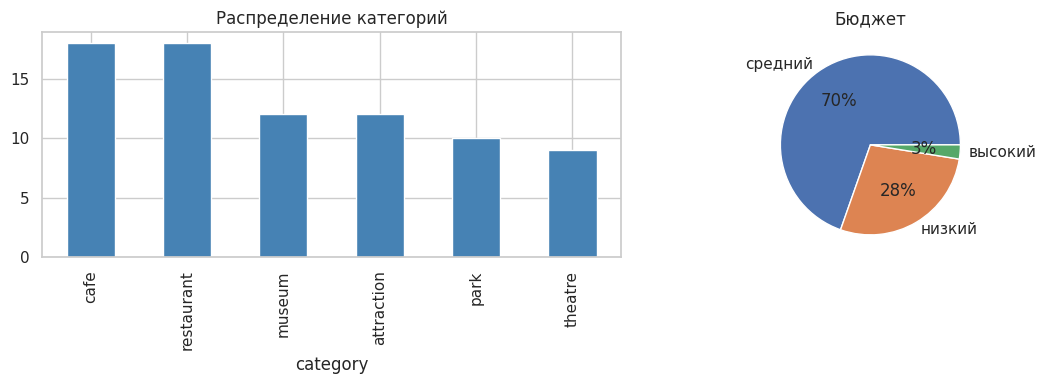

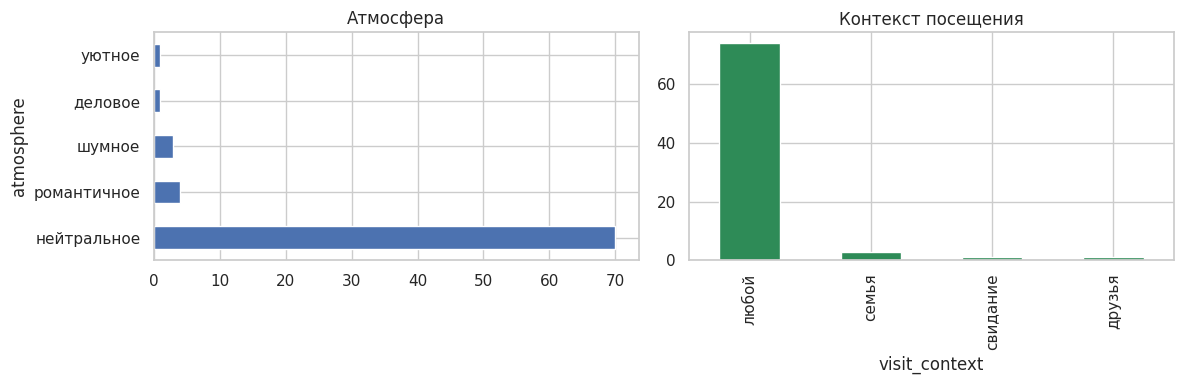

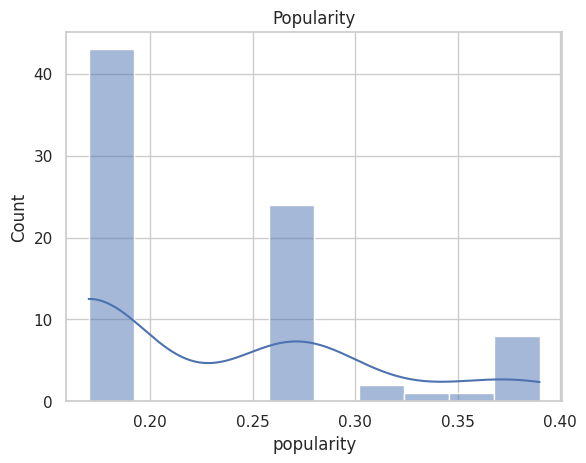

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_enriched["category"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Распределение категорий")
df_enriched["budget"].value_counts().plot(kind="pie", autopct="%1.0f%%", ax=axes[1])
axes[1].set_title("Бюджет")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

atm = df_enriched["atmosphere"].str.split(",").str[0].str.strip()
ctx = df_enriched["visit_context"].str.split(",").str[0].str.strip()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
atm.value_counts().plot(kind="barh", ax=axes[0])
axes[0].set_title("Атмосфера")
ctx.value_counts().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Контекст посещения")
plt.tight_layout()
plt.show()

sns.histplot(df_enriched["popularity"], bins=10, kde=True)
plt.title("Popularity")
plt.show()

## Задание 5. Семантический поиск

TF-IDF по тексту + извлечённым признакам, cosine similarity.

In [6]:
cols = ["name", "description", "reviews", "experience", "atmosphere", "visit_context", "budget"]
corpus = df_enriched[cols].fillna("").agg(" ".join, axis=1)
vec = TfidfVectorizer(ngram_range=(1, 2))
X = vec.fit_transform(corpus)

def search(query, top_k=5):
    sims = cosine_similarity(vec.transform([query]), X).flatten()
    idx = sims.argsort()[::-1][:top_k]
    out = df_enriched.iloc[idx][["name", "category", "atmosphere", "visit_context", "budget"]].copy()
    out["score"] = sims[idx]
    return out

search("уютное кафе для работы с ноутбуком")

,name,category,atmosphere,visit_context,budget,score
0,WoWфли,cafe,нейтральное,любой,средний,0.122586
14,Lamm’s,cafe,нейтральное,любой,средний,0.110150
3,Бахытик,cafe,нейтральное,любой,средний,0.102399
2,Мясная Машина,cafe,нейтральное,любой,средний,0.101901
11,Свидание на крыше,cafe,романтичное,свидание,средний,0.087172


In [7]:
queries = [
    "уютное кафе для работы",
    "романтический ужин",
    "куда сходить с детьми",
    "прогулка в парке",
    "современное искусство",
]
rows = []
for q in queries:
    for rank, (_, r) in enumerate(search(q, top_k=3).iterrows(), 1):
        rows.append({
            "query": q,
            "rank": rank,
            "name": r["name"],
            "category": r["category"],
            "score": round(float(r["score"]), 3),
        })
search_table = pd.DataFrame(rows)
search_table.to_csv(ROOT / "data" / "search_comparison.csv", index=False)
search_table

,query,rank,name,category,score
0,уютное кафе для работы,1,WoWфли,cafe,0.123
1,уютное кафе для работы,2,Lamm’s,cafe,0.110
2,уютное кафе для работы,3,Бахытик,cafe,0.102
3,романтический ужин,1,Патриаршие пруды,attraction,0.000
4,романтический ужин,2,Москва-Сити,attraction,0.000
5,романтический ужин,3,Детский мир,attraction,0.000
6,куда сходить с детьми,1,Патриаршие пруды,attraction,0.089
7,куда сходить с детьми,2,Москва-Сити,attraction,0.000
8,куда сходить с детьми,3,Детский мир,attraction,0.000
9,прогулка в парке,1,Музей современного искусства «Гараж»,museum,0.102


## Выводы

1. Необходимо больше данных и отзывы
2. Явные семантические теги + TF-IDF работают
3. можно попробовать добавить LLM
